In [1]:
#start here
import torch
from torch.utils.data import Dataset, DataLoader
from torch import nn
from transformers import AutoModel, AutoTokenizer
from datasets import load_dataset
import pandas as pd
import os
from torch.nn.utils.rnn import pad_sequence




# Define the Dataset class
class CustomDataset(Dataset):
    def __init__(self, df, text_col, label_col, max_len=64, sample=None):
        texts = df
        if sample:
            texts = texts.sample(sample)
        
        self.tokenizer = AutoTokenizer.from_pretrained(backbone)
        self.texts = texts[text_col].values.tolist()
        self.labels = None if label_col not in texts.columns else texts[label_col].values.tolist()
        self.max_len = max_len
    

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        res = self.tokenizer(
            self.texts[idx],
            return_tensors="pt",
            padding=False,
            max_length=self.max_len,
            truncation=True,
        )
        res = {k:v[0] for k,v in res.items()}
        res = {"input": res}
        if self.labels is not None:
            res["target"] = torch.tensor(self.labels[idx])
            
        return res
    
    
class Head(nn.Module):
    def __init__(self, layers, activation=nn.ReLU):
        super().__init__()
        my_layers = []
        
        for i in range(len(layers)-1):
            my_layers.append(nn.Linear(layers[i], layers[i+1]))
            if i< len(layers)-2:
                my_layers.append(activation())

        self.layers = nn.ModuleList(my_layers)
        
    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x


def dynamic_padding_collate_fn(batch):
    """
    Dynamic padding for batches, including category handling.
    Pads input sequences to the maximum length in the batch.
    """
    # Extract input_ids, attention_mask, token_type_ids from the batch
    input_ids = [item['input']['input_ids'] for item in batch]
    attention_mask = [item['input']['attention_mask'] for item in batch]
    token_type_ids = [item['input']['token_type_ids'] for item in batch]

    # Find the maximum sequence length in the batch
    max_length = max([len(seq) for seq in input_ids])

    # Pad sequences to the maximum length in the batch
    input_ids_padded = [torch.nn.functional.pad(seq, (0, max_length - len(seq)), value=0) for seq in input_ids]
    attention_mask_padded = [torch.nn.functional.pad(seq, (0, max_length - len(seq)), value=0) for seq in attention_mask]
    token_type_ids_padded = [torch.nn.functional.pad(seq, (0, max_length - len(seq)), value=0) for seq in token_type_ids]

    # Stack the padded sequences into a tensor
    input_ids_padded = torch.stack(input_ids_padded, dim=0)
    attention_mask_padded = torch.stack(attention_mask_padded, dim=0)
    token_type_ids_padded = torch.stack(token_type_ids_padded, dim=0)

    # Create the input dictionary
    input_dict = {
        'input_ids': input_ids_padded,
        'attention_mask': attention_mask_padded,
        'token_type_ids': token_type_ids_padded,
    }

    # Handle labels if they exist (regression or classification)
    if 'target' in batch[0]:
        labels = torch.tensor([item['target'] for item in batch], dtype=torch.float32)
        return {'input': input_dict, 'target': labels}

    # Handle categories if they exist
    if 'category' in batch[0]:
        categories = np.array([item['category'] for item in batch], dtype=object)  # Make sure it's an array
        # Convert categorical labels (if they are strings) to integers (or any numeric type)
        # You can use LabelEncoder from sklearn for encoding categorical variables, if needed
        if categories.dtype == 'object':  # If the categories are non-numeric (e.g., strings)
            from sklearn.preprocessing import LabelEncoder
            encoder = LabelEncoder()
            categories = encoder.fit_transform(categories)  # Encode to integers
        categories_tensor = torch.tensor(categories, dtype=torch.long)  # Convert to tensor

        return {'input': input_dict, 'category': categories_tensor}

    return {'input': input_dict}

# Pooling Layer Class with dynamic pooling options
class PoolingLayer(nn.Module):
    def __init__(self, pooling_type='max'):
        """
        Initialize pooling layer with the type of pooling ('avg', 'max', or 'attention').
        """
        super(PoolingLayer, self).__init__()
        self.pooling_type = pooling_type

    def forward(self, x, attention_mask=None):
        """
        Perform either average pooling, max pooling, or attention pooling over the token dimension,
        considering the attention mask.
        
        Args:
            x (Tensor): Tensor of shape (batch_size, seq_len, hidden_size)
            attention_mask (Tensor, optional): Tensor of shape (batch_size, seq_len). 
                                               1 for valid tokens, 0 for padding tokens. 
                                               Defaults to None, in which case no masking is applied.
        """
        # If attention_mask is provided, ensure it's a float tensor
        if attention_mask is not None:
            attention_mask = attention_mask.float()

            # Mask out the padding tokens by setting the attention mask to 0 where there's padding
            mask_expanded = attention_mask.unsqueeze(-1).expand_as(x)  # Shape: (batch_size, seq_len, hidden_size)
            x = x * mask_expanded  # Zero out padding positions

            # To avoid division by zero, count valid tokens in each sequence
            valid_tokens_count = mask_expanded.sum(dim=1)  # Shape: (batch_size, hidden_size)
            valid_tokens_count = valid_tokens_count.clamp(min=1)  # Avoid division by zero (min=1)

        if self.pooling_type == 'avg':
            # Average pooling across the token dimension (axis=1), considering the attention mask
            if attention_mask is not None:
                pooled = torch.sum(x, dim=1) / valid_tokens_count  # Sum over sequence, then normalize by count
            else:
                pooled = torch.mean(x, dim=1)

        elif self.pooling_type == 'max':
            # Max pooling across the token dimension (axis=1), considering the attention mask
            pooled, _ = torch.max(x, dim=1)  # We only need the max values, not the indices

        elif self.pooling_type == 'attention':
            if attention_mask is not None:
                # Attention-based pooling (weighted sum of hidden states)
                # Apply softmax to attention mask (to get normalized weights)
                attention_weights = attention_mask
                attention_weights = attention_weights - attention_weights.max(dim=1, keepdim=True)[0]  # For numerical stability
                attention_weights = torch.exp(attention_weights)  # Apply exponential (softmax-like scaling)
                attention_weights = attention_weights / attention_weights.sum(dim=1, keepdim=True)  # Normalize the attention weights

                # Weighted sum of hidden states using attention weights
                pooled = torch.sum(x * attention_weights.unsqueeze(-1), dim=1)  # Shape: (batch_size, hidden_size)
            else:
                # If no attention mask, fall back to simple average pooling
                pooled = torch.mean(x, dim=1)

        else:
            raise ValueError("pooling_type must be 'avg', 'max' or 'attention'")

        return pooled

class CustomModel(nn.Module):
    def __init__(self, backbone, num_outputs, pooling_type, hidden_layers=None, dropout=0.1, n_heads=8, layer_norm=True):
        super().__init__()
        
        self.backbone_name = backbone
        self.backbone = AutoModel.from_pretrained(backbone)
        self.pool = PoolingLayer(pooling_type)
        self.num_outputs = num_outputs

        hidden_layers = hidden_layers if hidden_layers else []
        hidden_layers = [self.backbone.config.hidden_size] + hidden_layers + [num_outputs]
        self.head = Head(hidden_layers)
        self.dropout = nn.Dropout(dropout)
        # Attention Layer: Multihead Attention
        self.multihead_attention = nn.MultiheadAttention(embed_dim=self.backbone.config.hidden_size, num_heads=n_heads, dropout=dropout)
        
        # Optional Layer Normalization
        if layer_norm:
            self.layer_norm = nn.LayerNorm(self.backbone.config.hidden_size)
        else:
            self.layer_norm = None
            
    def forward(self, x, print_shapes=False, apply_sigmoid=False):
        x = self.backbone(**x)["last_hidden_state"]

        if print_shapes:
            print("Backbone output shape:", x.shape)

        # Step 2: Permute the shape for multihead attention (shape: seq_len, batch_size, hidden_size)
        x = x.permute(1, 0, 2)  # (batch_size, seq_len, hidden_size) -> (seq_len, batch_size, hidden_size)

        # Step 3: Apply Multihead Attention
        attn_output, attn_weights = self.multihead_attention(x, x, x)  # Query, Key, Value are all the same
        
        # Apply Layer Normalization (if enabled)
        if self.layer_norm:
            attn_output = self.layer_norm(attn_output)
            
        # Step 4: Optional: apply dropout after attention
        #attn_output = self.dropout(attn_output)

        # Step 5: Permute back to original shape (batch_size, seq_len, hidden_size)
        attn_output = attn_output.permute(1, 0, 2)  # (seq_len, batch_size, hidden_size) -> (batch_size, seq_len, hidden_size)

        # Step 6: Apply pooling (max/avg/attention pooling)
        x = self.pool(attn_output)  # Pooling (depends on your pooling type)
        
        if print_shapes:
            print("Pool output shape", x.shape)
            
        x = self.head(x)
        
        x = self.dropout(x) 
        if print_shapes:
            print("Head output shape", x.shape)
            
        #if apply_sigmoid:
            #x = nn.functional.sigmoid(x)
            
        # reduce single dimension
        if self.num_outputs == 1:
            x = x.view(-1)
            
        return x



In [2]:
import torch
from sklearn.metrics import roc_auc_score, accuracy_score
from tqdm import tqdm
from torch.cuda.amp import autocast, GradScaler  # Import mixed precision utilities

# Define the accuracy function
def accuracy(x, y):
    return accuracy_score(x, [1* (num > 0.5) for num in y])

# Initialize the scaler for mixed precision
scaler = GradScaler()

def train_loop(train_dl, model, loss_fn, optimizer, scheduler, device, scaler,  log_every=1, max_grad_norm=5):
    losses = []
    lr_values = []
    size = len(train_dl)
    
    # Set the model to training mode - important for batch normalization and dropout layers
    model.train()
    
    pbar = tqdm(train_dl)
    for batch_idx, batch_dict in enumerate(pbar):
        x = batch_dict["input"]
        x = {k: v.to(device) for k, v in x.items()}

        # this is necessary for BCEWithLogitLoss
        y = batch_dict["target"].float().to(device)
        
        # Use autocast for mixed precision
        with autocast():  
            # Compute prediction and loss
            pred = model(x)   
            loss = loss_fn(pred, y)

        
        scaler.scale(loss).backward()

        # Apply gradient clipping to avoid exploding gradients
        if max_grad_norm is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)

        # Optimizer step using scaled gradients
        scaler.step(optimizer)
        scaler.update()

        # Update scheduler
        scheduler.step()
        optimizer.zero_grad()
        
        if batch_idx % log_every == 0:
            losses.append(loss.detach().cpu().item())
            lr_values.append(scheduler.get_lr()[0])
        
        loss, current = loss.item(), (batch_idx + 1)
        pbar.set_description(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
            
    return losses, lr_values

# Inference loop with mixed precision
def inference_loop(model, dataloader, device, **predict_kwargs):
    model.to(device)
    predictions = []
    labels = []
    
    model.eval()
    with torch.no_grad():
        for batch_dict in tqdm(dataloader):
            x = batch_dict["input"]
            x = {k: v.to(device) for k, v in x.items()}
            y = batch_dict.get("target")
            
            # Use autocast for mixed precision
            with autocast():
                pred = model(x, **predict_kwargs)
            
            predictions.extend(pred.cpu().tolist())
            
            if y is not None:
                labels.extend(y.cpu().tolist())
                
    return predictions, labels

def validation_loop(val_dl, model, val_metrics, device):
    predictions, labels = inference_loop(model, val_dl, device, apply_sigmoid=True)
    scores = {metric.__name__: metric(labels, predictions) for metric in val_metrics}
    return scores

def predict(model, test_dl, device, apply_sigmoid=True):
    model.to(device)
    predictions, _ = inference_loop(model, test_dl, device, apply_sigmoid=apply_sigmoid)
    return predictions

def train(model, train_dl, val_dl, loss, optimizer, scheduler, epochs, val_metrics, device):
    scores = []
    losses = []
    lr_rates = []
    
    model.to(device)

    for epoch in range(epochs):
        print(f"Epoch {epoch+1}/{epochs}\n-------------------------------")
        epoch_losses, epoch_lr_rates = train_loop(train_dl, model, loss, optimizer, scheduler, device, scaler)
        epoch_scores = validation_loop(val_dl, model, val_metrics, device)
        print(epoch_scores)
        scores.append(epoch_scores)
        losses.extend(epoch_losses)
        lr_rates.extend(epoch_lr_rates)
    
    print("Done!")
    return model, scores, losses, lr_rates

# Read the dataset
df = pd.read_csv("/kaggle/input/nie-pdl-24-mid-term-competition/train.csv")
df["FOLD"] = df.index % 5

df_train = df[df["FOLD"] != 0].reset_index(drop=True)
df_valid = df[df["FOLD"] == 0].reset_index(drop=True)

print(df_train.shape[0], df_valid.shape[0])



/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


5165 1292


In [3]:
# Load your CSV dataset
df = pd.read_csv("/kaggle/input/nie-pdl-24-mid-term-competition/train.csv")

# List of unique categories
categories = df['category'].unique()

# Split the dataset by category
category_data = {category: df[df['category'] == category] for category in categories}

print(categories)

['Programming' 'Mathematics' 'Physics' 'Astronomy' 'Chemistry' 'Biology']


In [4]:
print(df_train['question'][1])
category_map = {
    'Programming': 0,
    'Mathematics': 1,
    'Physics': 2,
    'Astronomy': 3,
    'Chemistry': 4,
    'Biology': 5,
    'other': 6  # A default category for unmatched labels
}


# Function to prepend category number to question
def add_category_number(row):
    category_number = category_map.get(row['category'], -1)  # Default to -1 if category not found
    return f"{category_number} {row['question']}"

# Apply the function to the DataFrame
df_train['question_with_category'] = df_train.apply(add_category_number, axis=1)
df_train['question'] = df_train.apply(add_category_number, axis=1)
df_train['question'] = df_train.apply(add_category_number, axis=1)
#df_train['question'] = df_train['question'].str[:5]

print(df_train['question_with_category'][1])

When a prom magnetic field is applied perpendicular to a wire, what determines the magnitude and the direction of the electric current induced in the wire?
2 When a prom magnetic field is applied perpendicular to a wire, what determines the magnitude and the direction of the electric current induced in the wire?


In [5]:
torch.cuda.empty_cache()
print("cache emptied")

import gc
gc.collect()

torch.cuda.empty_cache()
print("cache emptied")

import gc
gc.collect()

cache emptied
cache emptied


0

Epoch 1/8
-------------------------------


100%|██████████| 646/646 [00:09<00:00, 67.11it/s]


{'mean_absolute_error': 1.2877777383054374}
Epoch 2/8
-------------------------------


100%|██████████| 646/646 [00:09<00:00, 68.56it/s]


{'mean_absolute_error': 1.4104517886513157}
Epoch 3/8
-------------------------------


...

100%|██████████| 646/646 [00:09<00:00, 67.13it/s]


{'mean_absolute_error': 1.1984504250919117}
Epoch 8/8
-------------------------------


100%|██████████| 646/646 [00:09<00:00, 68.53it/s]


{'mean_absolute_error': 1.1982627845031928}
Done!


,mean_absolute_error
epoch,
0,1.287778
1,1.410452
2,1.294941
3,1.179654
4,1.190378
5,1.189727
6,1.198450
7,1.198263


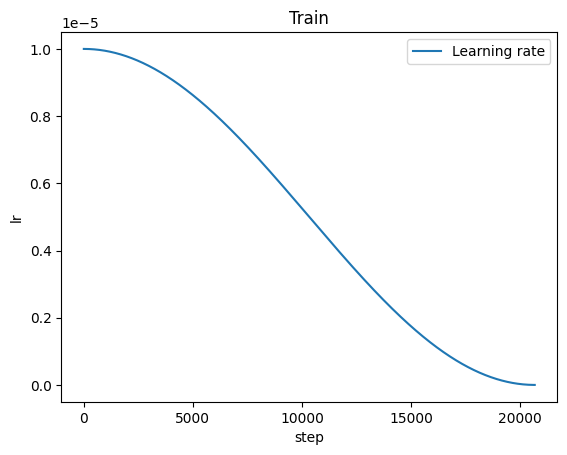

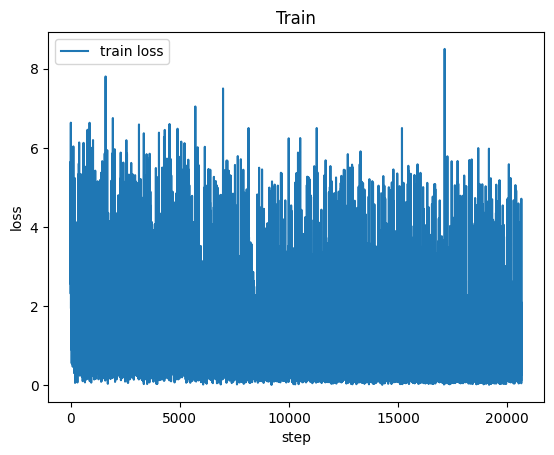

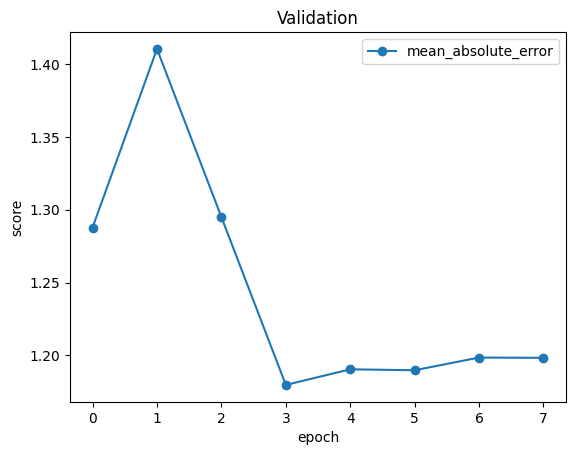

In [6]:
import torch
import matplotlib.pyplot as plt
from transformers import get_cosine_schedule_with_warmup
from sklearn.metrics import mean_absolute_error


# Specify all hyper-parameters
backbone = "google-bert/bert-base-cased"
learning_rate = 1e-5
num_classes = 1
hidden_layers = None
epochs = 8
batch_size= 2
device = "cuda"
pooling_type = "avg"
val_metrics = [mean_absolute_error]
loss = nn.L1Loss()
sample = None
dropout = 0.03
n_heads=8
model = CustomModel(backbone, num_classes, pooling_type, hidden_layers, dropout)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

#train valid data
#sample = 1000

train_ds = CustomDataset(df_train, "question", "difficulty", sample=sample)
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, collate_fn=dynamic_padding_collate_fn)

val_ds = CustomDataset(df_valid, "question", "difficulty", sample=sample)
val_dl = DataLoader(val_ds, batch_size=batch_size, shuffle=False, collate_fn=dynamic_padding_collate_fn)


# Get scheduler
scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=epochs * len(train_dl))

# Train model
model, val_scores, train_losses, lr_rates = train(model, train_dl, val_dl, loss, optimizer, scheduler, epochs, val_metrics, device)

# Save model weights
torch.save(model.state_dict(), 'model_weights.pth')

# Plot Learning Rates
pd.DataFrame({"Learning rate":lr_rates}).plot(xlabel="step", ylabel="lr", style="-", title="Train")

# Plot Train Losses
pd.DataFrame({"train loss":train_losses}).plot(xlabel="step", ylabel="loss", style="-", title="Train")

# Plot Validation Metrics
pd.DataFrame(val_scores).plot(xlabel="epoch", ylabel="score", style="o-", title="Validation")

# Show validation metrics
val_scores_df = pd.DataFrame(val_scores)
val_scores_df.index.name = "epoch"
val_scores_df

## Let's make predictions for the test dataset

In [7]:

# Get test dataset and data loader
test_df = pd.read_csv("/kaggle/input/nie-pdl-24-mid-term-competition/test.csv")
test_ds = CustomDataset(test_df, "question", "label")
test_dl = DataLoader(test_ds, batch_size=batch_size, shuffle=False, collate_fn=dynamic_padding_collate_fn)

# Define model and load weights
loaded_model = CustomModel(backbone, num_classes, pooling_type, hidden_layers)
loaded_model = CustomModel(backbone, 1, pooling_type ,None)

print("Loading weights")
loaded_model.load_state_dict(torch.load('model_weights.pth'))

# Set model to inference mode
loaded_model.eval()

# Predict on test data
preds = predict(loaded_model, test_dl, "cuda")


Loading weights


100%|██████████| 1000/1000 [00:14<00:00, 68.70it/s]


In [8]:
assert len(preds) == test_df.shape[0]

val_score = round(val_scores_df.iloc[-1, 0], 4)
sub = pd.DataFrame({"id": test_df["id"].values, "difficulty": preds})
file_name = f"sub_{val_score}.csv"
sub.to_csv(file_name, index=False)
print(file_name)
sub.head()

sub_1.1983.csv


,id,difficulty
0,1809,4.207031
1,1416,3.962891
2,2089,9.484375
3,948,1.068359
4,1431,7.050781
